# LAB2 - Bài 5

## Câu a

In [1]:
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn import tree
from sklearn.naive_bayes import GaussianNB
from sklearn import metrics

In [2]:
data = pd.read_csv('./Dataset/heart.csv')

In [3]:
data.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2,1
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2,1
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2,1
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2,1


Đặng Phan Duy - 6451071010

In [4]:
print("Number of data before:", len(data))
# Xóa các dòng dữ liệu trống
data = data.replace('?', np.nan).dropna()
print("Number of data after:", len(data))

Number of data before: 303
Number of data after: 303


Đặng Phan Duy - 6451071010

In [5]:
# Sửa tên các cột dữ liệu
data.columns = ['age', 'sex', 'chest_pain_type', 'resting_blood_pressure', 'cholesterol',
                'fasting_blood_sugar', 'rest_ecg', 'max_heart_rate_achieved', 'exercise_induced_angina',
                'st_depression', 'st_slope', 'num_major_vessels', 'thalassemia', 'target']
data.head()

,age,sex,chest_pain_type,resting_blood_pressure,cholesterol,fasting_blood_sugar,rest_ecg,max_heart_rate_achieved,exercise_induced_angina,st_depression,st_slope,num_major_vessels,thalassemia,target
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2,1
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2,1
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2,1
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2,1


Đặng Phan Duy - 6451071010

In [6]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   age                      303 non-null    int64  
 1   sex                      303 non-null    int64  
 2   chest_pain_type          303 non-null    int64  
 3   resting_blood_pressure   303 non-null    int64  
 4   cholesterol              303 non-null    int64  
 5   fasting_blood_sugar      303 non-null    int64  
 6   rest_ecg                 303 non-null    int64  
 7   max_heart_rate_achieved  303 non-null    int64  
 8   exercise_induced_angina  303 non-null    int64  
 9   st_depression            303 non-null    float64
 10  st_slope                 303 non-null    int64  
 11  num_major_vessels        303 non-null    int64  
 12  thalassemia              303 non-null    int64  
 13  target                   303 non-null    int64  
dtypes: float64(1), int64(13)
m

Đặng Phan Duy - 6451071010

In [7]:
data['target'].value_counts()

target
1    165
0    138
Name: count, dtype: int64

Đặng Phan Duy - 6451071010

## Câu b

### Yêu cầu 3

<Axes: >

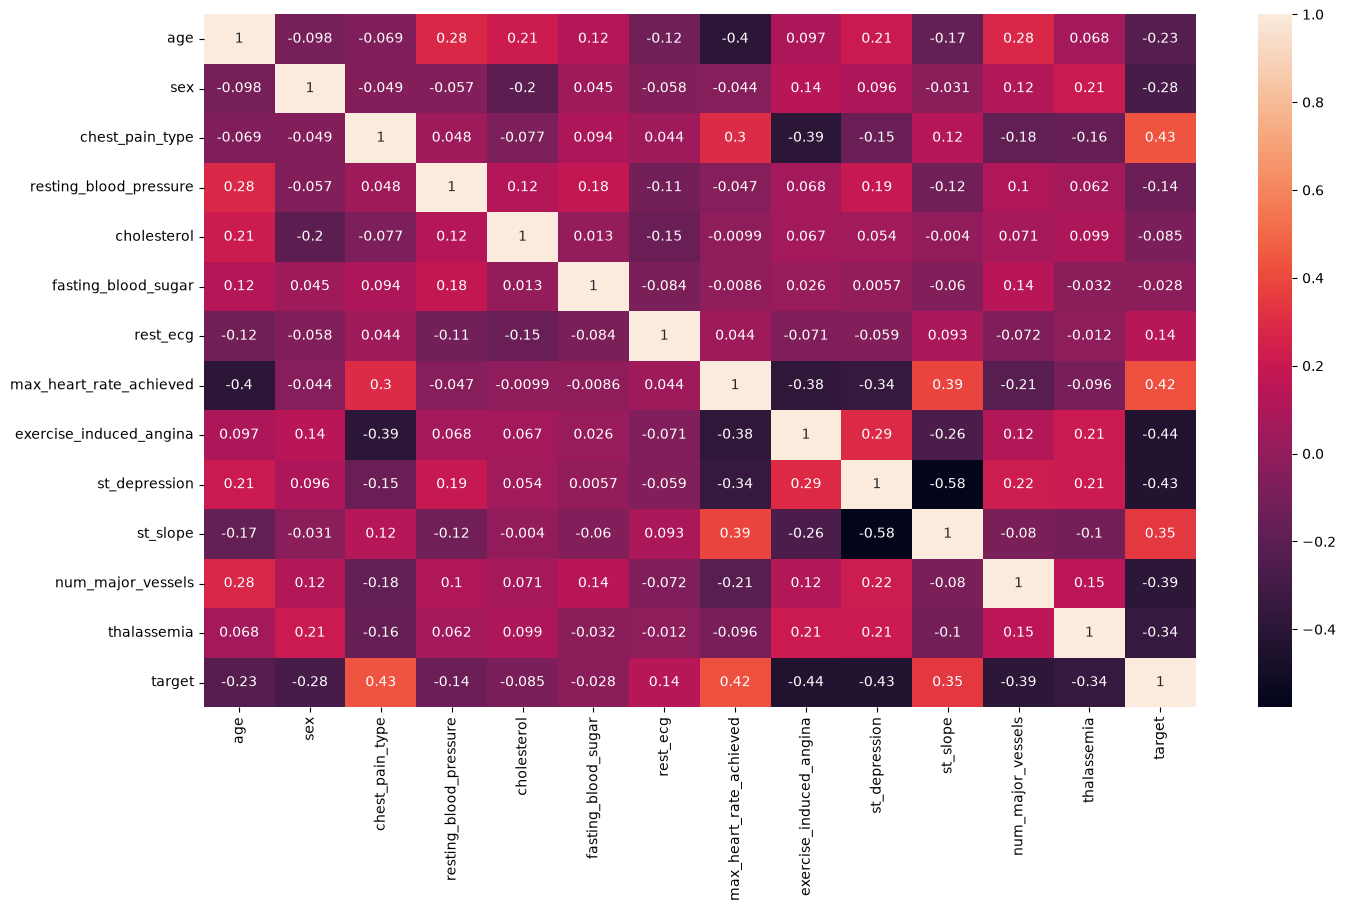

In [8]:
plt.figure(figsize=(16,9))
sns.heatmap(data.corr(method='pearson'), annot=True)

Đặng Phan Duy - 6451071010

In [9]:
# Liệt kê các cặp thuộc tính có độ tương đồng cao (|r| > 0.65)
corr = data.drop('target', axis=1).corr(method='pearson')
high_corr = [(corr.index[i], corr.columns[j], round(corr.iloc[i, j], 3))
             for i in range(len(corr)) for j in range(i + 1, len(corr))
             if abs(corr.iloc[i, j]) > 0.65]
pd.DataFrame(high_corr, columns=['Thuộc tính 1', 'Thuộc tính 2', 'Pearson'])

,Thuộc tính 1,Thuộc tính 2,Pearson


Đặng Phan Duy - 6451071010

Nhận xét: không có cặp thuộc tính nào có độ tương đồng cao (giá trị lớn nhất là |r| ≈ 0.58 giữa 'st_depression' và 'st_slope'), nên không cần loại bỏ cột nào.

### Yêu cầu 4

In [10]:
features = data.drop('target', axis=1)
labels = data['target']

### Yêu cầu 5

In [11]:
features.select_dtypes(exclude=['number']).columns

Index([], dtype='object')

Đặng Phan Duy - 6451071010

Nhận xét: tất cả các thuộc tính đều đã ở dạng số nên không cần chuyển đổi về dạng one-hot vector.

### Yêu cầu 6

In [12]:
X = features
y = labels
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

In [13]:
print("Number of training data:", len(X_train))
print("Number of test data:", len(X_test))

Number of training data: 212
Number of test data: 91


Đặng Phan Duy - 6451071010

### Yêu cầu 7

In [14]:
clf = tree.DecisionTreeClassifier(criterion="entropy", random_state=0)
#Train Decision Tree Classifer
clf.fit(X_train, y_train)

,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'entropy'
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",0
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of sampl

Đặng Phan Duy - 6451071010

In [15]:
#Predict the response for test dataset
tree_pred = clf.predict(X_test)

# Model Accuracy, how often is the classifier correct?
tree_score = metrics.accuracy_score(y_test, tree_pred)
print("Accuracy:", tree_score)
print("Report:", metrics.classification_report(y_test, tree_pred, zero_division=0))

Accuracy: 0.7252747252747253
Report:               precision    recall  f1-score   support

           0       0.67      0.76      0.71        41
           1       0.78      0.70      0.74        50

    accuracy                           0.73        91
   macro avg       0.73      0.73      0.72        91
weighted avg       0.73      0.73      0.73        91



Đặng Phan Duy - 6451071010

In [16]:
tree_cm = metrics.confusion_matrix(y_test, tree_pred, labels=clf.classes_)

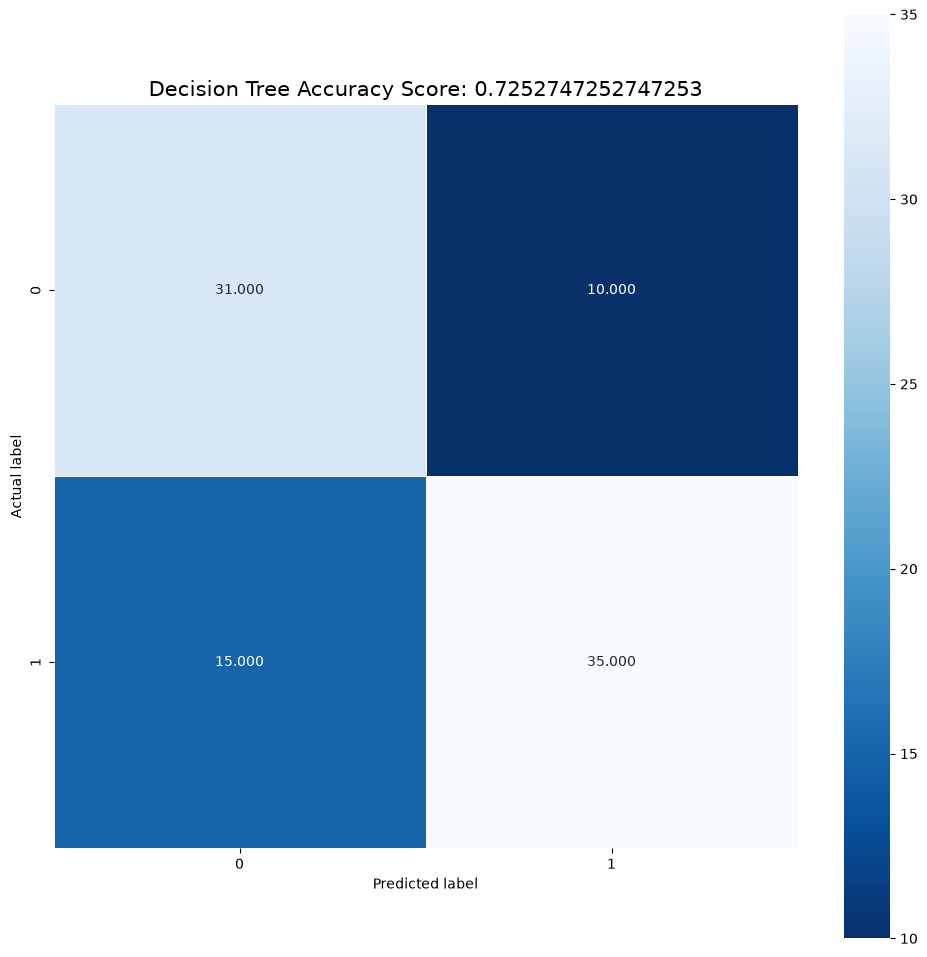

In [17]:
plt.figure(figsize=(12,12))
sns.heatmap(tree_cm, annot=True, fmt=".3f", linewidths=.5, square = True, cmap = 'Blues_r',
            xticklabels=clf.classes_, yticklabels=clf.classes_);
plt.ylabel('Actual label');
plt.xlabel('Predicted label');
title = 'Decision Tree Accuracy Score: {0}'.format(tree_score)
plt.title(title, size = 15);

Đặng Phan Duy - 6451071010

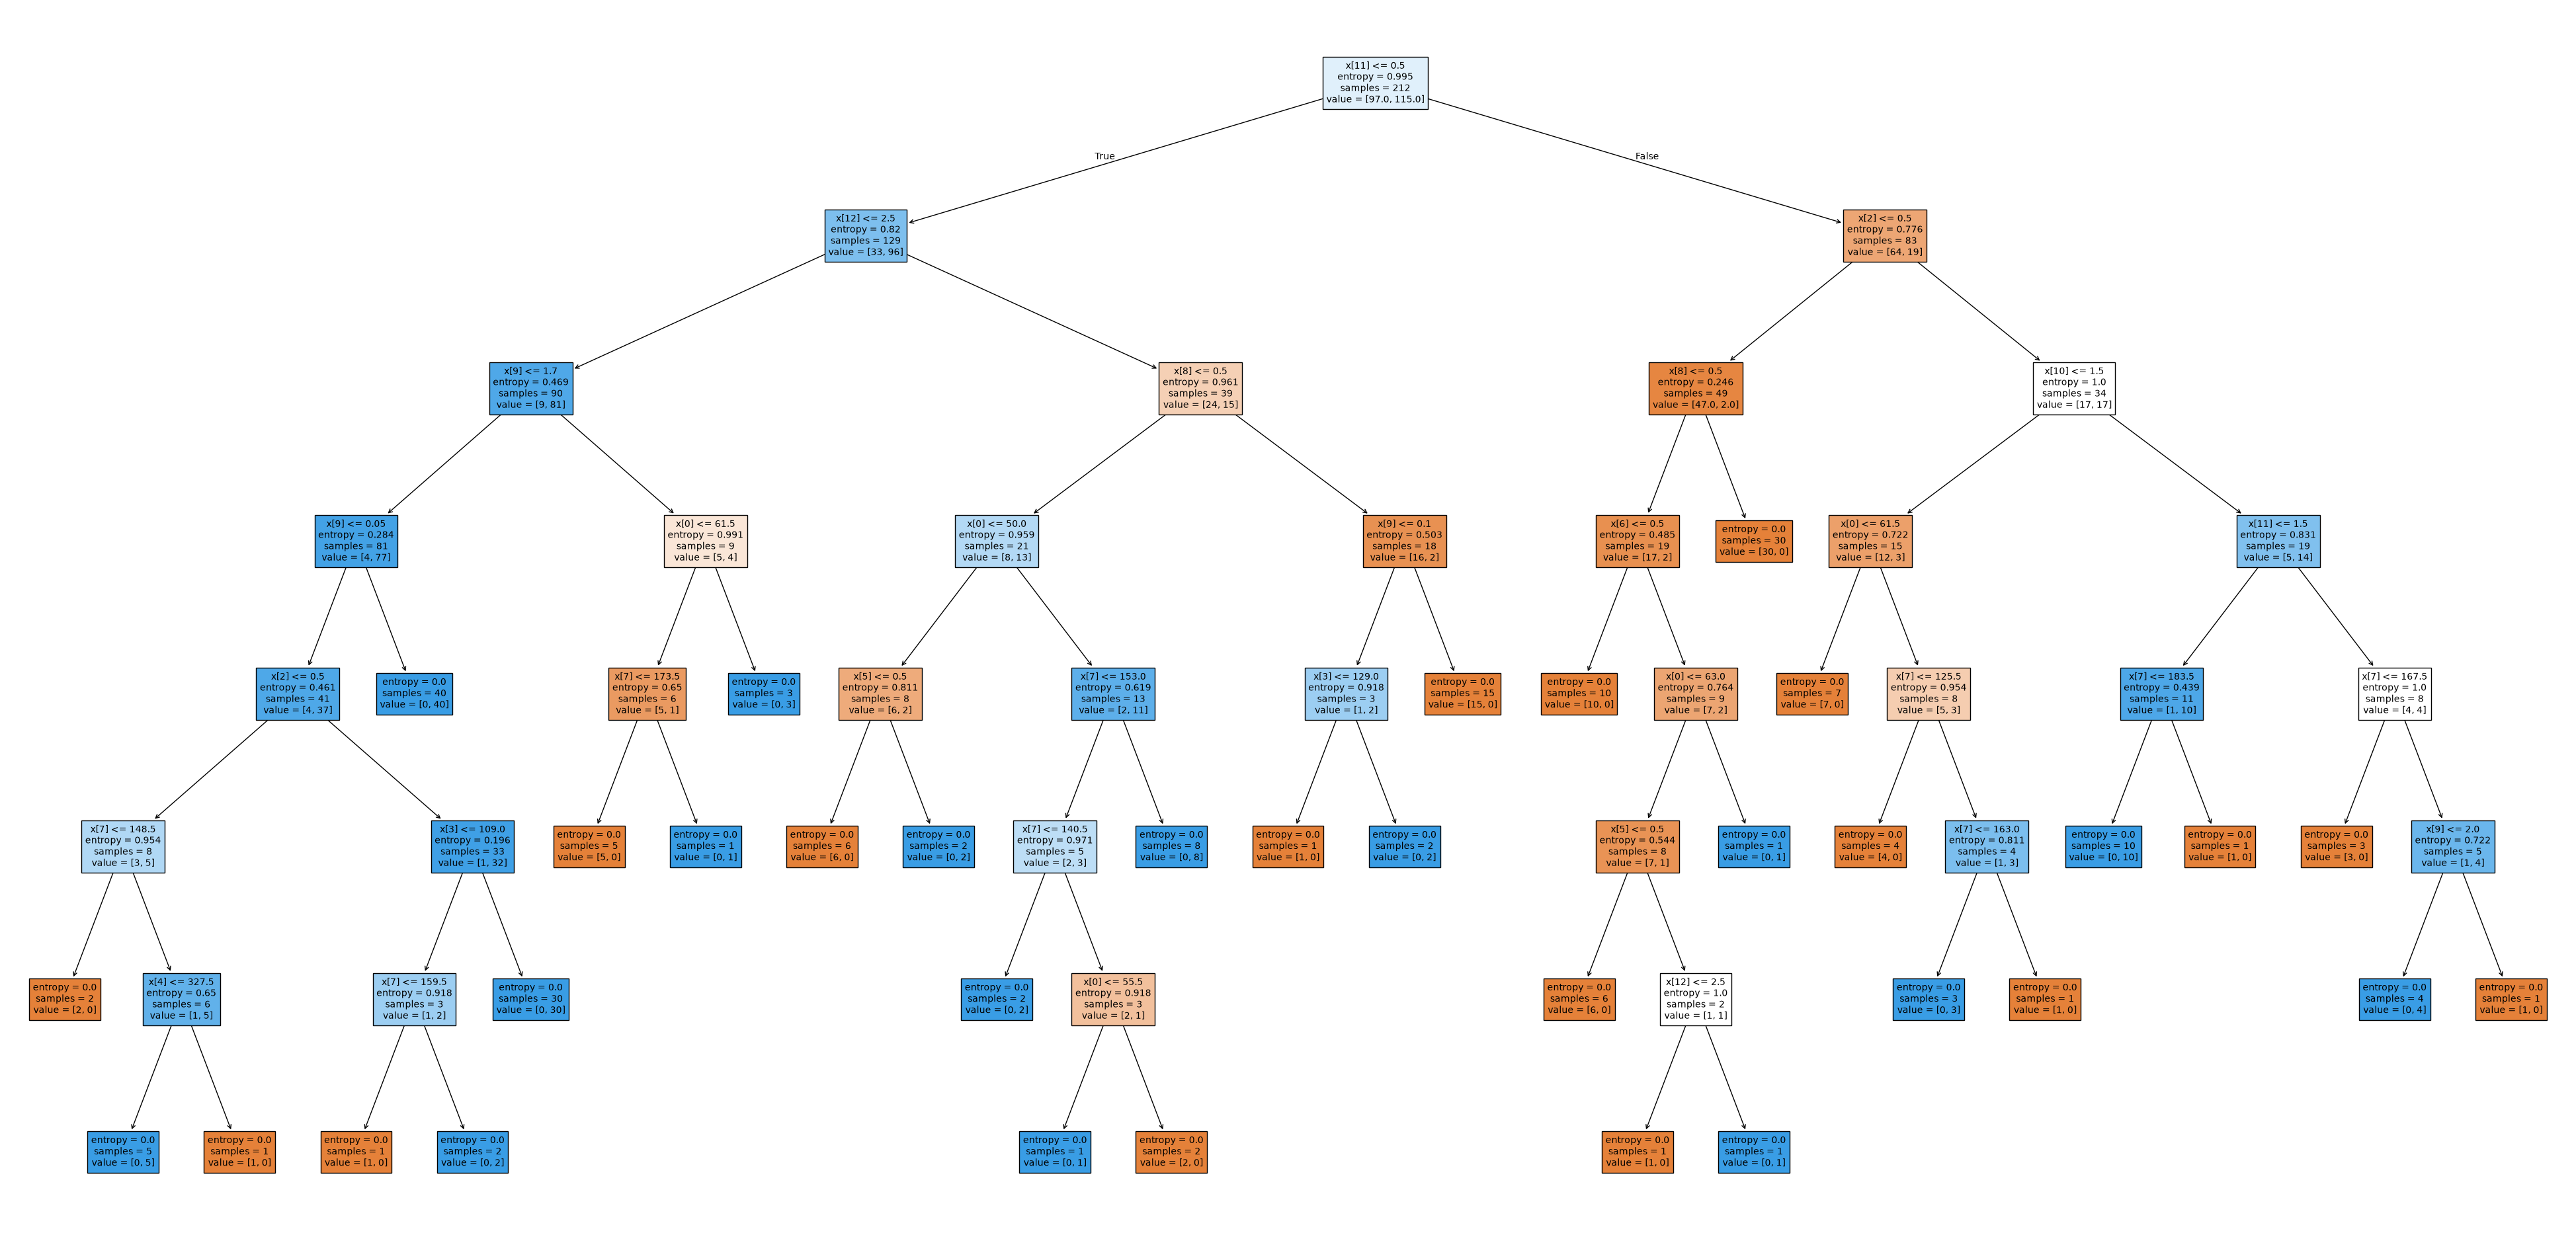

In [18]:
fig, ax = plt.subplots(figsize=(50, 24))
tree.plot_tree(clf, filled=True, fontsize=10)
plt.savefig('decision_tree', dpi=100)
plt.show()

Đặng Phan Duy - 6451071010

### Yêu cầu 8

In [19]:
clf_gini = tree.DecisionTreeClassifier(criterion="gini", random_state=0)
#Train Decision Tree Classifer
clf_gini.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",0
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples 

Đặng Phan Duy - 6451071010

In [20]:
#Predict the response for test dataset
gini_pred = clf_gini.predict(X_test)

# Model Accuracy, how often is the classifier correct?
gini_score = metrics.accuracy_score(y_test, gini_pred)
print("Accuracy:", gini_score)
print("Report:", metrics.classification_report(y_test, gini_pred, zero_division=0))

Accuracy: 0.7252747252747253
Report:               precision    recall  f1-score   support

           0       0.67      0.76      0.71        41
           1       0.78      0.70      0.74        50

    accuracy                           0.73        91
   macro avg       0.73      0.73      0.72        91
weighted avg       0.73      0.73      0.73        91



Đặng Phan Duy - 6451071010

In [21]:
gini_cm = metrics.confusion_matrix(y_test, gini_pred, labels=clf_gini.classes_)

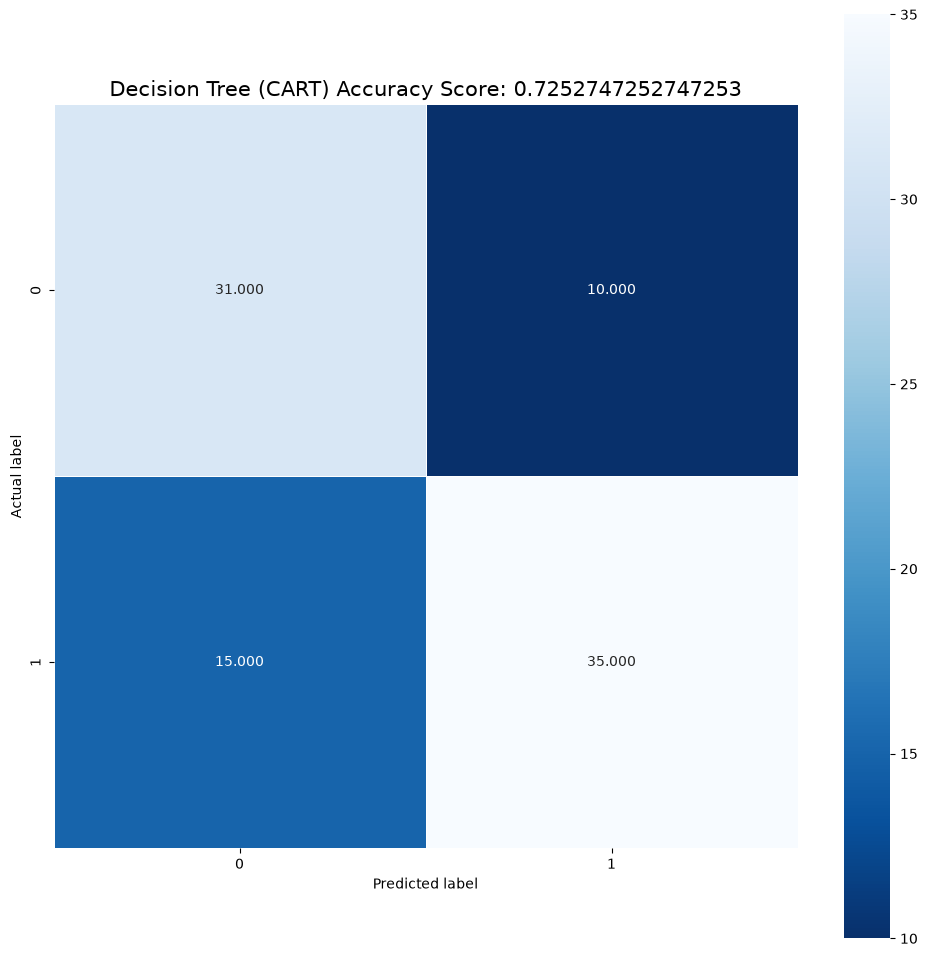

In [22]:
plt.figure(figsize=(12,12))
sns.heatmap(gini_cm, annot=True, fmt=".3f", linewidths=.5, square = True, cmap = 'Blues_r',
            xticklabels=clf_gini.classes_, yticklabels=clf_gini.classes_);
plt.ylabel('Actual label');
plt.xlabel('Predicted label');
title = 'Decision Tree (CART) Accuracy Score: {0}'.format(gini_score)
plt.title(title, size = 15);

Đặng Phan Duy - 6451071010

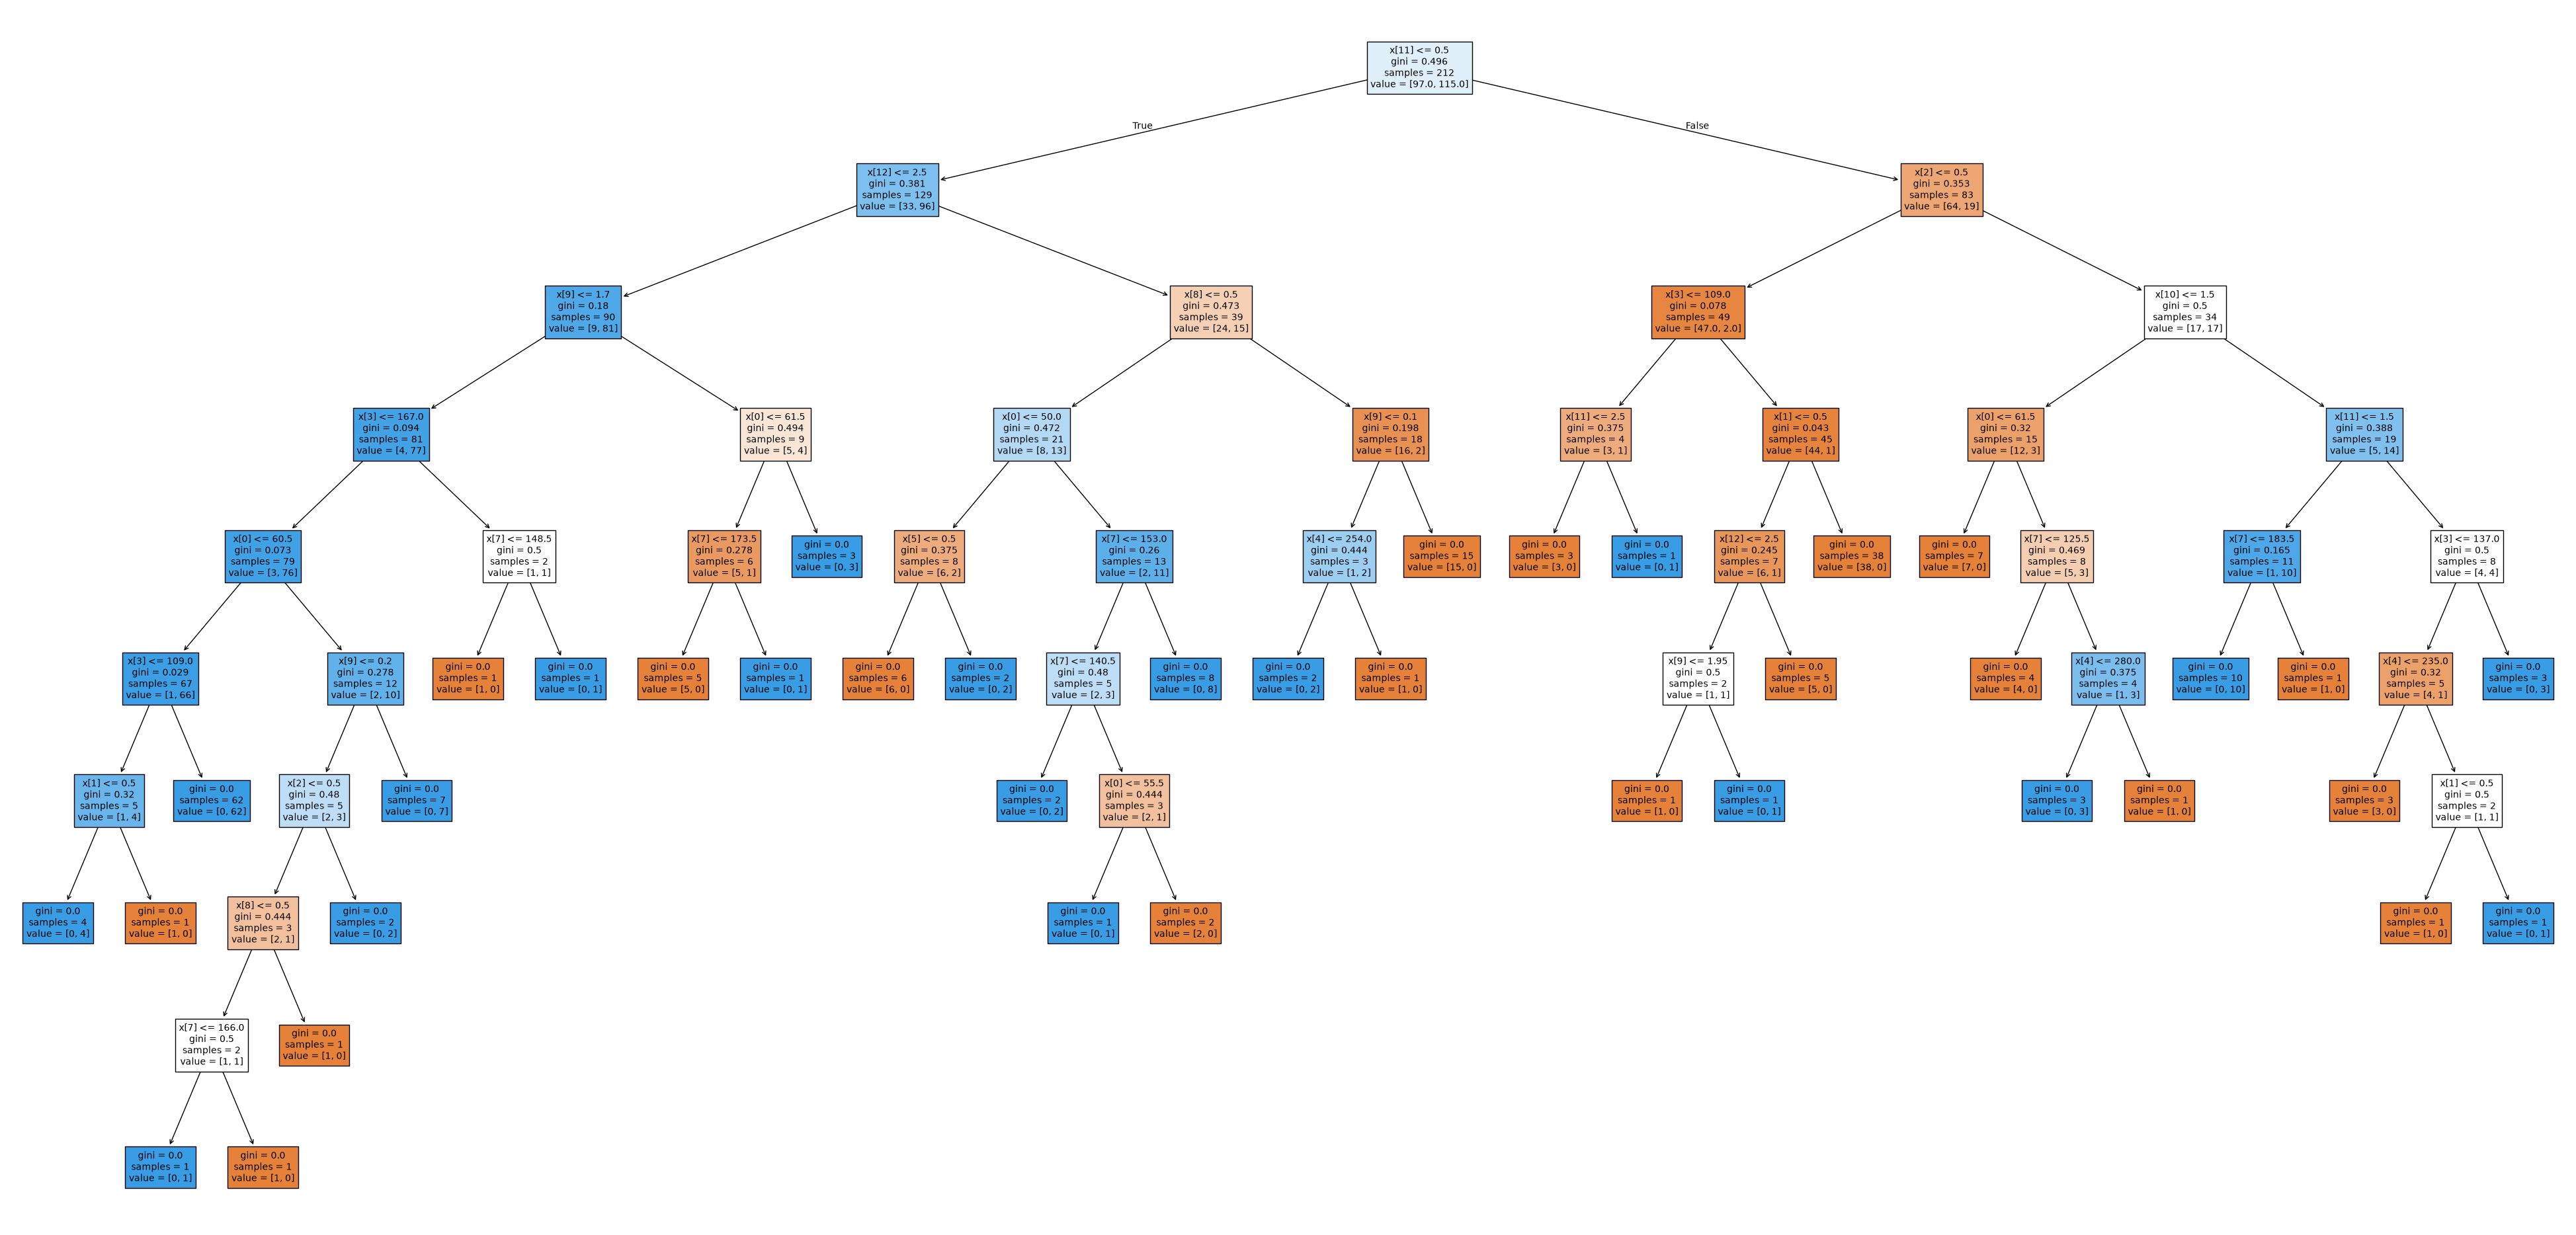

In [23]:
fig, ax = plt.subplots(figsize=(50, 24))
tree.plot_tree(clf_gini, filled=True, fontsize=10)
plt.savefig('decision_tree_gini', dpi=100)
plt.show()

Đặng Phan Duy - 6451071010

### Yêu cầu 9

In [24]:
gnb = GaussianNB()
bayes_pred = gnb.fit(X_train, y_train).predict(X_test)

In [25]:
# Model Accuracy, how often is the classifier correct?
bayes_score = metrics.accuracy_score(y_test, bayes_pred)
print("Accuracy:", bayes_score)
print("Report:", metrics.classification_report(y_test, bayes_pred, zero_division=0))

Accuracy: 0.8351648351648352
Report:               precision    recall  f1-score   support

           0       0.78      0.88      0.83        41
           1       0.89      0.80      0.84        50

    accuracy                           0.84        91
   macro avg       0.84      0.84      0.83        91
weighted avg       0.84      0.84      0.84        91



Đặng Phan Duy - 6451071010

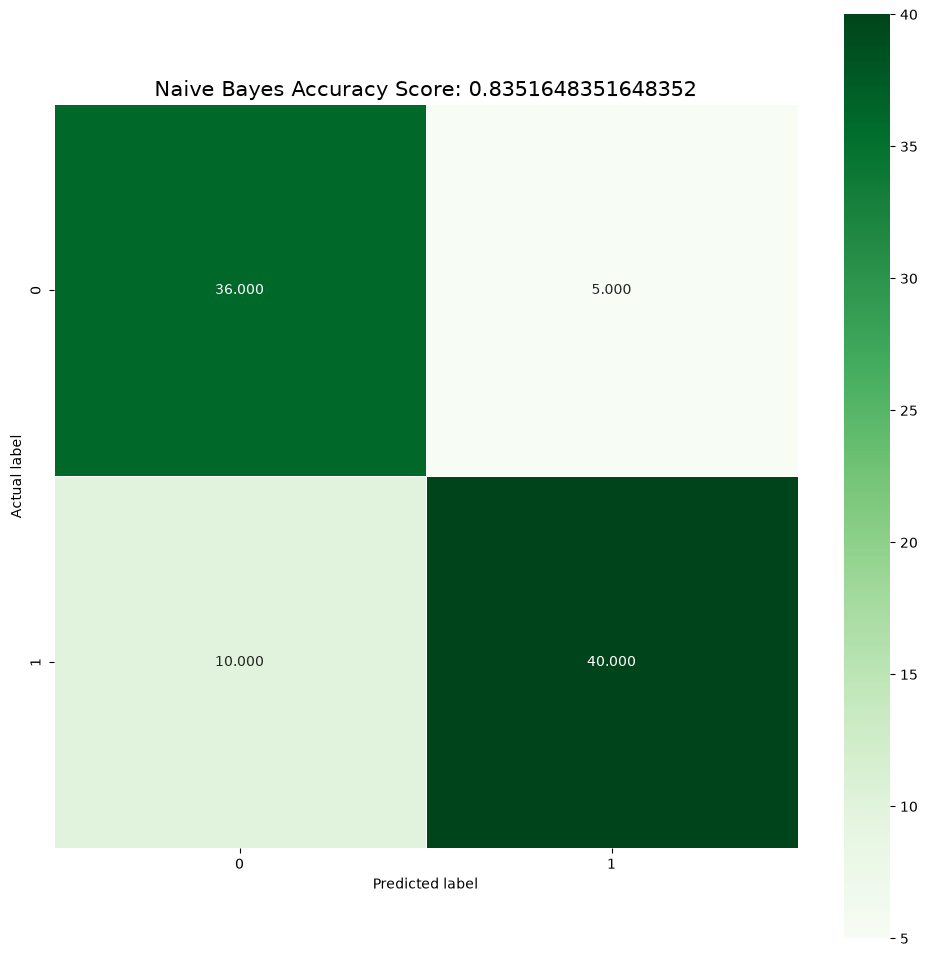

In [26]:
bayes_cm = metrics.confusion_matrix(y_test, bayes_pred, labels=gnb.classes_)

plt.figure(figsize=(12,12))
sns.heatmap(bayes_cm, annot=True, fmt=".3f", linewidths=.5, square = True, cmap = 'Greens',
            xticklabels=gnb.classes_, yticklabels=gnb.classes_);
plt.ylabel('Actual label');
plt.xlabel('Predicted label');
title = 'Naive Bayes Accuracy Score: {0}'.format(bayes_score)
plt.title(title, size = 15);

Đặng Phan Duy - 6451071010

### Yêu cầu 10

In [27]:
preds = [tree_pred, gini_pred, bayes_pred]
results = pd.DataFrame({
    'Model': ['ID3', 'CART', 'Naive Bayes'],
    'Accuracy': [metrics.accuracy_score(y_test, p) for p in preds],
    'Precision (1)': [metrics.precision_score(y_test, p, pos_label=1) for p in preds],
    'Recall (1)': [metrics.recall_score(y_test, p, pos_label=1) for p in preds],
    'F1 (1)': [metrics.f1_score(y_test, p, pos_label=1) for p in preds],
    'Precision (0)': [metrics.precision_score(y_test, p, pos_label=0) for p in preds],
    'Recall (0)': [metrics.recall_score(y_test, p, pos_label=0) for p in preds]
})
results

,Model,Accuracy,Precision (1),Recall (1),F1 (1),Precision (0),Recall (0)
0,ID3,0.725275,0.777778,0.7,0.736842,0.673913,0.756098
1,CART,0.725275,0.777778,0.7,0.736842,0.673913,0.756098
2,Naive Bayes,0.835165,0.888889,0.8,0.842105,0.782609,0.878049


Đặng Phan Duy - 6451071010

Nhận xét:

- Hai cây quyết định ID3 và CART cho kết quả giống hệt nhau trên tập kiểm thử: accuracy ≈ 0.725, trong đó lớp 1 (có bệnh tim) có precision ≈ 0.78 và recall = 0.70, lớp 0 có precision ≈ 0.67 và recall ≈ 0.76. Hai cây có thể khác nhau về cấu trúc, nhưng dự đoán trên 91 mẫu kiểm thử lại trùng nhau. Mỗi cây dự đoán đúng 66/91 mẫu và bỏ sót 15 bệnh nhân có bệnh tim.
- Naïve Bayes cho kết quả tốt nhất ở tất cả các chỉ số: accuracy ≈ 0.835, lớp 1 có precision ≈ 0.89 và recall = 0.80, lớp 0 có precision ≈ 0.78 và recall ≈ 0.88. Mô hình dự đoán đúng 76/91 mẫu và chỉ bỏ sót 10 bệnh nhân có bệnh tim.
- Nguyên nhân là dữ liệu khá nhỏ (chỉ 212 mẫu huấn luyện) và các thuộc tính hầu như không tương đồng với nhau (|r| lớn nhất ≈ 0.58), nên phù hợp với giả định độc lập của Naïve Bayes. Ngược lại, hai cây quyết định phát triển đến khi các nút lá thuần nhất nên dễ bị quá khớp (overfitting) khi dữ liệu ít.
- Trong bài toán chẩn đoán bệnh, recall của lớp 1 rất quan trọng vì bỏ sót người bệnh nguy hiểm hơn chẩn đoán nhầm người khỏe mạnh. Vì vậy trên dữ liệu Heart Disease, Naïve Bayes là mô hình phù hợp hơn hai cây quyết định. Do tập kiểm thử chỉ có 91 mẫu nên kết quả có thể thay đổi khá nhiều nếu đổi random_state.